<a href="https://colab.research.google.com/github/Divyesh-SP/DSA0405-FUNDAMENTALS-OF-DATA-SCIENCE/blob/main/FODS_ASSIGNMENT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA04 – Fundamentals of Data Science (CO2)
## Air-Quality Monitoring: Reproducible Pre-processing and Visualisation Pipeline

**How to use:** Open this notebook in Google Colab and run cells from top to bottom. It generates a reproducible synthetic dataset, performs Tasks 1–11, prints tables and saves figures.

**Dataset note:** The assignment permits a synthetic dataset. This notebook creates 100 stations and 12 months of hourly readings (876,000 rows), then creates supplier-format examples (CSV, Excel and JSON). Synthetic results are for demonstrating the pipeline, not for making real public-health claims.

## Setup and imports

In [1]:
import os, json, time, platform, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
BASE = Path("air_quality_project")
RAW, PROCESSED, FIGURES, CODE = [BASE/x for x in ["data/raw","data/processed","figures","code"]]
for folder in [RAW, PROCESSED, FIGURES, CODE]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Random seed:", SEED)

Python: 3.13.18
NumPy: 2.4.6 | Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Random seed: 42


## Generate reproducible synthetic data (100 stations × 8,760 hours)

In [2]:
dates = pd.date_range("2025-01-01", "2025-12-31 23:00:00", freq="h", tz="UTC")
n_stations = 100
stations = pd.DataFrame({
    "station_id": [f"S{i:03d}" for i in range(1, n_stations+1)],
    "station_name": [f"Station {i:03d}" for i in range(1, n_stations+1)],
    "district": [f"District {((i-1)//10)+1:02d}" for i in range(1, n_stations+1)],
    "zone_type": np.resize(["residential","industrial","traffic"], n_stations),
    "altitude_m": np.random.randint(5, 250, n_stations),
    "installation_date": pd.to_datetime("2018-01-01") + pd.to_timedelta(np.random.randint(0, 2000, n_stations), unit="D")
})
station_idx = np.repeat(np.arange(n_stations), len(dates))
ts = np.tile(dates, n_stations)
zone_effect = stations["zone_type"].map({"residential":0, "industrial":18, "traffic":12}).to_numpy()[station_idx]
hour_effect = 8*np.sin(2*np.pi*pd.DatetimeIndex(ts).hour.to_numpy()/24)
season_effect = 10*np.sin(2*np.pi*(pd.DatetimeIndex(ts).dayofyear.to_numpy()/365))
pm25 = np.maximum(2, 28 + zone_effect + hour_effect + season_effect + np.random.normal(0,8,len(ts)))
raw = pd.DataFrame({
    "station_id": stations.station_id.to_numpy()[station_idx],
    "timestamp": ts,
    "PM2.5": pm25,
    "PM10": pm25*1.65 + np.random.normal(0,5,len(ts)),
    "NO2": 18 + zone_effect*.45 + np.random.normal(0,5,len(ts)),
    "temperature_C": 28 + 5*np.sin(2*np.pi*pd.DatetimeIndex(ts).dayofyear.to_numpy()/365) + np.random.normal(0,2,len(ts)),
    "humidity_pct": np.clip(65 + np.random.normal(0,12,len(ts)), 15, 100)
})
# Inject realistic quality issues: missing values, sentinel values, invalid negatives, duplicates and spikes
for col in ["PM2.5","PM10","NO2","temperature_C","humidity_pct"]:
    miss = np.random.choice(raw.index, size=int(0.06*len(raw)), replace=False)
    raw.loc[miss, col] = np.nan
    sent = np.random.choice(raw.index, size=int(0.003*len(raw)), replace=False)
    raw.loc[sent, col] = -999
    neg = np.random.choice(raw.index, size=int(0.001*len(raw)), replace=False)
    raw.loc[neg, col] = -abs(raw.loc[neg, col].fillna(1))
spike = np.random.choice(raw.index, size=500, replace=False)
raw.loc[spike, "PM2.5"] *= 8
raw = pd.concat([raw, raw.sample(300, random_state=SEED)], ignore_index=True)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
stations.to_csv(RAW/"station_master.csv", index=False)
raw.to_csv(RAW/"supplier_A.csv", index=False)
print("Station count:", stations.station_id.nunique())
print("Hourly readings including injected duplicate rows:", len(raw))
print("Date range:", raw.timestamp.min(), "to", raw.timestamp.max())
print("Columns:", raw.columns.tolist())
display(raw.head())

Station count: 100
Hourly readings including injected duplicate rows: 876300
Date range: 2025-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00
Columns: ['station_id', 'timestamp', 'PM2.5', 'PM10', 'NO2', 'temperature_C', 'humidity_pct']


,station_id,timestamp,PM2.5,PM10,NO2,temperature_C,humidity_pct
0,S001,2025-01-01 00:00:00+00:00,30.553337,51.712493,20.708937,26.611452,56.433473
1,S001,2025-01-01 01:00:00+00:00,22.017760,35.868745,14.070006,28.826353,62.329816
2,S001,2025-01-01 02:00:00+00:00,20.823362,37.234230,17.082620,24.658955,70.186431
3,S001,2025-01-01 03:00:00+00:00,35.351684,62.875517,18.940674,28.854755,61.466175
4,S001,2025-01-01 04:00:00+00:00,36.186367,67.060246,14.603747,31.211244,60.845055


## Create supplier B (Excel, alternate names/units) and supplier C (JSON)

In [4]:

# Supplier B: Excel with alternate column names and units

b = raw.drop_duplicates(["station_id", "timestamp"]).sample(
    2000, random_state=SEED
).copy()

b["PM25_mg_m3"] = b["PM2.5"] / 1000

b = b.rename(columns={
    "station_id": "site_code",
    "timestamp": "reading_time",
    "PM10": "pm10_ugm3",
    "NO2": "no2_ugm3"
})

# FIX: Remove timezone information for Excel compatibility
b["reading_time"] = pd.to_datetime(
    b["reading_time"], utc=True
).dt.tz_localize(None)

b[["site_code", "reading_time", "PM25_mg_m3",
   "pm10_ugm3", "no2_ugm3"]].to_excel(
    RAW / "supplier_B.xlsx", index=False
)


# Supplier C: JSON with alternate column names

c = raw.drop_duplicates(["station_id", "timestamp"]).sample(
    1500, random_state=SEED
).copy()

c = c.rename(columns={
    "station_id": "station",
    "timestamp": "time_utc",
    "PM2.5": "pm25",
    "PM10": "pm10"
})

c[["station", "time_utc", "pm25", "pm10", "NO2"]].to_json(
    RAW / "supplier_C.json",
    orient="records",
    date_format="iso"
)

print("Created supplier_A.csv, supplier_B.xlsx and supplier_C.json")


Created supplier_A.csv, supplier_B.xlsx and supplier_C.json


## TASK 1 – Environment and reproducible project set-up

In [5]:
library_roles = pd.DataFrame({
    "Library":["NumPy","SciPy","scikit-learn","Pandas","Matplotlib"],
    "Role":["Fast numerical arrays","Scientific statistics and z-scores","Imputation, encoding and scaling","Reading, cleaning and grouping tables","Charts and visualisation"],
    "Example function":["np.where()","stats.zscore()","SimpleImputer()","pd.read_csv()","plt.plot()"]
})
display(library_roles)
print("\nFolder structure:")
for p in [RAW, PROCESSED, FIGURES, CODE]:
    print(p)
sample = pd.read_csv(RAW/"supplier_A.csv", nrows=8, parse_dates=["timestamp"])
print("\nSample shape:", sample.shape)
print("\nData types:\n", sample.dtypes)
display(sample.head())
print("Raw data is retained unchanged; all cleaned outputs are written to data/processed.")

,Library,Role,Example function
0,NumPy,Fast numerical arrays,np.where()
1,SciPy,Scientific statistics and z-scores,stats.zscore()
2,scikit-learn,"Imputation, encoding and scaling",SimpleImputer()
3,Pandas,"Reading, cleaning and grouping tables",pd.read_csv()
4,Matplotlib,Charts and visualisation,plt.plot()



Folder structure:
air_quality_project/data/raw
air_quality_project/data/processed
air_quality_project/figures
air_quality_project/code

Sample shape: (8, 7)

Data types:
 station_id                    object
timestamp        datetime64[ns, UTC]
PM2.5                        float64
PM10                         float64
NO2                          float64
temperature_C                float64
humidity_pct                 float64
dtype: object


,station_id,timestamp,PM2.5,PM10,NO2,temperature_C,humidity_pct
0,S001,2025-01-01 00:00:00+00:00,30.553337,51.712493,20.708937,26.611452,56.433473
1,S001,2025-01-01 01:00:00+00:00,22.017760,35.868745,14.070006,28.826353,62.329816
2,S001,2025-01-01 02:00:00+00:00,20.823362,37.234230,17.082620,24.658955,70.186431
3,S001,2025-01-01 03:00:00+00:00,35.351684,62.875517,18.940674,28.854755,61.466175
4,S001,2025-01-01 04:00:00+00:00,36.186367,67.060246,14.603747,31.211244,60.845055


Raw data is retained unchanged; all cleaned outputs are written to data/processed.


## TASK 2 – Reading and selecting data

In [6]:
# Read CSV with explicit types and date parsing
dtype_map = {"station_id":"category"}
df = pd.read_csv(RAW/"supplier_A.csv", dtype=dtype_map, parse_dates=["timestamp"], na_values=["-999"])
print("CSV shape:", df.shape, "| unique stations:", df.station_id.nunique())
print("Memory (MB):", round(df.memory_usage(deep=True).sum()/1024**2,2))
print("First timestamp:", df.timestamp.min(), "| Last timestamp:", df.timestamp.max())
display(df.head(3)); display(df.tail(3))

# Excel and JSON readers
df_b = pd.read_excel(RAW/"supplier_B.xlsx", parse_dates=["reading_time"])
df_c = pd.read_json(RAW/"supplier_C.json")
print("Excel shape:", df_b.shape, "| JSON shape:", df_c.shape)

# Selection by label, position, boolean condition and query
print("\nLabel selection:\n", df.loc[:2, ["station_id","timestamp","PM2.5"]])
print("\nPosition selection:\n", df.iloc[:3, :4])
industrial = df.merge(stations[["station_id","zone_type"]], on="station_id")
industrial_monsoon = industrial[(industrial.zone_type=="industrial") & (industrial.timestamp.dt.month.isin([6,7,8,9]))]
print("Industrial monsoon records:", len(industrial_monsoon))
print("Query example rows:", len(df.query("`PM2.5` > 50")))

# Large-file read comparison
t0=time.perf_counter(); full=pd.read_csv(RAW/"supplier_A.csv"); full_time=time.perf_counter()-t0
t0=time.perf_counter(); selected=pd.read_csv(RAW/"supplier_A.csv", usecols=["station_id","timestamp","PM2.5"], dtype={"station_id":"category"}); selected_time=time.perf_counter()-t0
full_mem=full.memory_usage(deep=True).sum()/1024**2
sel_mem=selected.memory_usage(deep=True).sum()/1024**2
print(f"Full read: {full_time:.3f}s, {full_mem:.2f} MB")
print(f"Selected columns: {selected_time:.3f}s, {sel_mem:.2f} MB")

CSV shape: (876300, 7) | unique stations: 100
Memory (MB): 40.96
First timestamp: 2025-01-01 00:00:00+00:00 | Last timestamp: 2025-12-31 23:00:00+00:00


,station_id,timestamp,PM2.5,PM10,NO2,temperature_C,humidity_pct
0,S001,2025-01-01 00:00:00+00:00,30.553337,51.712493,20.708937,26.611452,56.433473
1,S001,2025-01-01 01:00:00+00:00,22.017760,35.868745,14.070006,28.826353,62.329816
2,S001,2025-01-01 02:00:00+00:00,20.823362,37.234230,17.082620,24.658955,70.186431


,station_id,timestamp,PM2.5,PM10,NO2,temperature_C,humidity_pct
876297,S058,2025-11-19 00:00:00+00:00,16.220705,23.379040,18.160122,25.848575,69.008992
876298,S045,2025-11-14 07:00:00+00:00,37.007984,58.192249,20.790359,26.863719,66.784641
876299,S010,2025-10-26 06:00:00+00:00,NaN,46.277331,15.911939,28.345717,76.424637


Excel shape: (2000, 5) | JSON shape: (1500, 5)

Label selection:
   station_id                 timestamp      PM2.5
0       S001 2025-01-01 00:00:00+00:00  30.553337
1       S001 2025-01-01 01:00:00+00:00  22.017760
2       S001 2025-01-01 02:00:00+00:00  20.823362

Position selection:
   station_id                 timestamp      PM2.5       PM10
0       S001 2025-01-01 00:00:00+00:00  30.553337  51.712493
1       S001 2025-01-01 01:00:00+00:00  22.017760  35.868745
2       S001 2025-01-01 02:00:00+00:00  20.823362  37.234230
Industrial monsoon records: 96652
Query example rows: 167720
Full read: 1.058s, 139.56 MB
Selected columns: 0.841s, 69.37 MB


## TASK 3 – Missing-data audit and treatments

,missing_count,missing_percent
PM2.5,54984,6.27
PM10,54988,6.28
NO2,55001,6.28
temperature_C,54971,6.27
humidity_pct,54993,6.28


Missing after sentinel/invalid conversion:


,missing
PM2.5,55857
PM10,57470
NO2,55923
temperature_C,55844
humidity_pct,55869


/tmp/ipykernel_456/1045725734.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ff[numeric_cols]=ff.groupby("station_id")[numeric_cols].ffill(limit=2)
/tmp/ipykernel_456/1045725734.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  interp["PM2.5_interp"]=interp.groupby("station_id")["PM2.5"].transform(lambda s: s.interpolate(limit=3, limit_area="inside"))


,method,rows,mean,std
0,Original valid values,820443,38.06,15.71
1,Drop missing PM2.5,820443,38.06,15.71
2,Forward fill (limit=2),876086,38.06,15.73
3,Interpolate (limit=3),876270,38.06,15.60


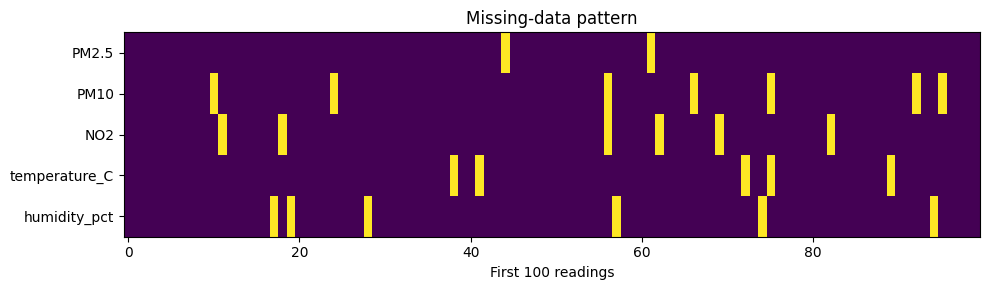

Rule: do not interpolate long gaps, maintenance periods, or gaps spanning abrupt pollution events.


In [7]:
numeric_cols=["PM2.5","PM10","NO2","temperature_C","humidity_pct"]
audit=pd.DataFrame({"missing_count":df[numeric_cols].isna().sum(),
                    "missing_percent":(df[numeric_cols].isna().mean()*100).round(2)})
display(audit)
# Convert impossible values to missing
clean=df.copy()
for col in numeric_cols:
    clean.loc[clean[col] == -999, col] = np.nan
    clean.loc[clean[col] < 0, col] = np.nan
clean.loc[clean["humidity_pct"] > 100, "humidity_pct"] = np.nan
print("Missing after sentinel/invalid conversion:")
display(clean[numeric_cols].isna().sum().to_frame("missing"))

# Treatment 1: drop rows missing PM2.5
drop_pm=clean.dropna(subset=["PM2.5"])
# Treatment 2: limited forward fill within station
ff=clean.sort_values(["station_id","timestamp"]).copy()
ff[numeric_cols]=ff.groupby("station_id")[numeric_cols].ffill(limit=2)
# Treatment 3: time interpolation for PM2.5 per station (short gaps only)
interp=clean.sort_values(["station_id","timestamp"]).copy()
interp["PM2.5_interp"]=interp.groupby("station_id")["PM2.5"].transform(lambda s: s.interpolate(limit=3, limit_area="inside"))
compare=pd.DataFrame({
    "method":["Original valid values","Drop missing PM2.5","Forward fill (limit=2)","Interpolate (limit=3)"],
    "rows":[clean["PM2.5"].notna().sum(),drop_pm["PM2.5"].notna().sum(),ff["PM2.5"].notna().sum(),interp["PM2.5_interp"].notna().sum()],
    "mean":[clean["PM2.5"].mean(),drop_pm["PM2.5"].mean(),ff["PM2.5"].mean(),interp["PM2.5_interp"].mean()],
    "std":[clean["PM2.5"].std(),drop_pm["PM2.5"].std(),ff["PM2.5"].std(),interp["PM2.5_interp"].std()]
})
display(compare.round(2))
# Missingness heatmap sample
plt.figure(figsize=(10,3))
plt.imshow(clean[numeric_cols].isna().head(100).T, aspect="auto", interpolation="nearest")
plt.yticks(range(len(numeric_cols)),numeric_cols); plt.xlabel("First 100 readings"); plt.title("Missing-data pattern")
plt.tight_layout(); plt.savefig(FIGURES/"task3_missing_pattern.png",dpi=150); plt.show()
print("Rule: do not interpolate long gaps, maintenance periods, or gaps spanning abrupt pollution events.")

## TASK 4 – Sorting, grouping and ranking

In [8]:
valid=clean.dropna(subset=["PM2.5"]).merge(stations[["station_id","district","zone_type"]],on="station_id")
sorted_data=valid.sort_values(["district","PM2.5"],ascending=[True,False],na_position="last")
display(sorted_data[["station_id","district","PM2.5"]].head())
station_summary=valid.groupby("station_id",observed=True).agg(
    mean_pm25=("PM2.5","mean"), max_pm25=("PM2.5","max"), readings=("PM2.5","count")).reset_index()
station_summary=station_summary.merge(stations[["station_id","district","zone_type"]],on="station_id")
station_summary["rank"]=station_summary["mean_pm25"].rank(method="min",ascending=False).astype(int)
district_summary=valid.groupby("district").agg(mean_pm25=("PM2.5","mean"), max_pm25=("PM2.5","max"), readings=("PM2.5","count")).reset_index()
district_summary["rank"]=district_summary.mean_pm25.rank(method="min",ascending=False).astype(int)
display(station_summary.sort_values("rank").head(10))
display(district_summary.sort_values("rank"))
pivot=valid.pivot_table(index="district",columns="zone_type",values="PM2.5",aggfunc="mean")
display(pivot.round(2))
print("Reconciliation – grouped valid readings:", station_summary.readings.sum(), "| raw valid readings:", valid["PM2.5"].notna().sum())
print("Grouping caution: convert timestamps to one timezone before daily/monthly grouping; otherwise readings near midnight may enter the wrong day.")

,station_id,district,PM2.5
73758,S009,District 01,488.526760
68291,S009,District 01,474.267330
60862,S008,District 01,470.257933
43175,S006,District 01,455.040582
66793,S009,District 01,448.380258


,station_id,mean_pm25,max_pm25,readings,district,zone_type,rank
94,S095,46.435264,460.524469,8222,District 10,industrial,1
52,S053,46.432654,441.419855,8167,District 06,industrial,2
10,S011,46.430456,521.573600,8164,District 02,industrial,3
4,S005,46.391916,432.209933,8207,District 01,industrial,4
76,S077,46.329436,464.277812,8190,District 08,industrial,5
88,S089,46.315644,485.846284,8237,District 09,industrial,6
34,S035,46.272331,456.711447,8163,District 04,industrial,7
64,S065,46.255175,454.961717,8225,District 07,industrial,8
19,S020,46.243473,505.960306,8197,District 02,industrial,9
7,S008,46.210991,470.257933,8182,District 01,industrial,10


,district,mean_pm25,max_pm25,readings,rank
1,District 02,39.018353,521.573600,82070,1
7,District 08,38.932539,481.288069,82147,2
4,District 05,38.891379,518.862737,82104,3
8,District 09,38.367466,509.766749,82094,4
5,District 06,38.339946,585.645586,81925,5
2,District 03,38.320394,429.262747,82043,6
6,District 07,37.204735,560.876396,81988,7
9,District 10,37.189553,596.698463,81985,8
0,District 01,37.157914,488.526760,81987,9
3,District 04,37.151372,525.288352,82100,10


zone_type,industrial,residential,traffic
district,,,
District 01,46.24,28.11,40.12
District 02,46.23,28.26,40.17
District 03,46.06,28.22,40.09
District 04,46.20,28.16,40.13
District 05,46.13,28.05,40.04
District 06,46.22,28.09,40.14
District 07,46.14,28.23,40.22
District 08,46.16,28.19,40.09
District 09,46.15,28.13,40.20


Reconciliation – grouped valid readings: 820443 | raw valid readings: 820443
Grouping caution: convert timestamps to one timezone before daily/monthly grouping; otherwise readings near midnight may enter the wrong day.


## TASK 5 – NumPy and SciPy numerical computing

In [9]:
x=np.random.default_rng(SEED).uniform(1,100,size=500_000)
# Example pollution index from three pollutants
a=np.column_stack([x, x*1.4, x*.6])
weights=np.array([0.5,0.3,0.2])
t0=time.perf_counter()
loop_result=np.array([row[0]*.5+row[1]*.3+row[2]*.2 for row in a])
loop_time=time.perf_counter()-t0
t0=time.perf_counter()
vector_result=a @ weights
vector_time=time.perf_counter()-t0
print("Loop seconds:",round(loop_time,4),"Vector seconds:",round(vector_time,4))
print("Speed-up:",round(loop_time/max(vector_time,1e-12),2),"x")
print("Correctness (allclose):",np.allclose(loop_result,vector_result))
# Broadcasting: subtract each pollutant mean from each row
centered=a-a.mean(axis=0)
print("Broadcasting output shape:",centered.shape)
z=stats.zscore(x)
print("SciPy z-score mean:",round(float(np.mean(z)),5),"std:",round(float(np.std(z)),5))
# Hand check: [10,20,30] with weights [.5,.3,.2] = 17
hand=np.array([10,20,30]) @ weights
print("Hand-check result (expected 17):",hand)
x32=a.astype(np.float32); x64=a.astype(np.float64)
print("float32 MB:",round(x32.nbytes/1024**2,2),"float64 MB:",round(x64.nbytes/1024**2,2))
print("Max absolute precision difference:",np.max(np.abs(x64-x32)))

Loop seconds: 1.1839 Vector seconds: 0.0096
Speed-up: 123.12 x
Correctness (allclose): True
Broadcasting output shape: (500000, 3)
SciPy z-score mean: -0.0 std: 1.0
Hand-check result (expected 17): 17.0
float32 MB: 5.72 float64 MB: 11.44
Max absolute precision difference: 7.629294543676224e-06


## TASK 6 – Transformation with Pandas and scikit-learn (leakage-safe)

In [10]:
model_df=clean.merge(stations[["station_id","zone_type"]],on="station_id")
model_df=model_df.sort_values("timestamp")
# Standardise timestamps to UTC and PM2.5 units to micrograms/m3
model_df["timestamp"]=pd.to_datetime(model_df["timestamp"],utc=True)
# Normalise categorical spelling
model_df["zone_type"]=model_df["zone_type"].str.lower().replace({"industrial area":"industrial","residential area":"residential"})
# Temporal split: first 9 months train, final 3 months test
train_mask=model_df.timestamp < "2025-10-01"
train=model_df.loc[train_mask].copy()
test=model_df.loc[~train_mask].copy()
features=["PM2.5","PM10","NO2","temperature_C","humidity_pct"]
numeric_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",RobustScaler())])
categorical_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])
preprocessor=ColumnTransformer([("num",numeric_pipe,features),("cat",categorical_pipe,["zone_type"])])
X_train=preprocessor.fit_transform(train[features+["zone_type"]])
X_test=preprocessor.transform(test[features+["zone_type"]])
print("Train rows:",len(train),"Test rows:",len(test))
print("Transformed train shape:",X_train.shape,"Test shape:",X_test.shape)
# Compare scaling methods on training PM2.5
scaling=pd.DataFrame({"raw":train["PM2.5"].dropna().describe(),
 "standard":pd.Series(StandardScaler().fit_transform(train[["PM2.5"]].dropna()).ravel()).describe(),
 "minmax":pd.Series(MinMaxScaler().fit_transform(train[["PM2.5"]].dropna()).ravel()).describe(),
 "robust":pd.Series(RobustScaler().fit_transform(train[["PM2.5"]].dropna()).ravel()).describe()})
display(scaling.round(3))
print("RobustScaler is selected because median/IQR scaling is less affected by injected spikes.")
print("No leakage: imputer/scaler/encoder are fitted on Jan–Sep only, then applied to Oct–Dec.")

Train rows: 655436 Test rows: 220864
Transformed train shape: (655436, 8) Test shape: (220864, 8)


,raw,standard,minmax,robust
count,613531.000,613531.000,613531.000,613531.000
mean,40.195,0.000,0.064,-0.008
std,15.726,1.000,0.026,0.806
min,2.000,-2.429,0.000,-1.966
25%,30.420,-0.622,0.048,-0.509
50%,40.357,0.010,0.064,0.000
75%,49.934,0.619,0.081,0.491
max,596.698,35.389,1.000,28.511


RobustScaler is selected because median/IQR scaling is less affected by injected spikes.
No leakage: imputer/scaler/encoder are fitted on Jan–Sep only, then applied to Oct–Dec.


## TASK 7 – Matplotlib visualisation (five figures)

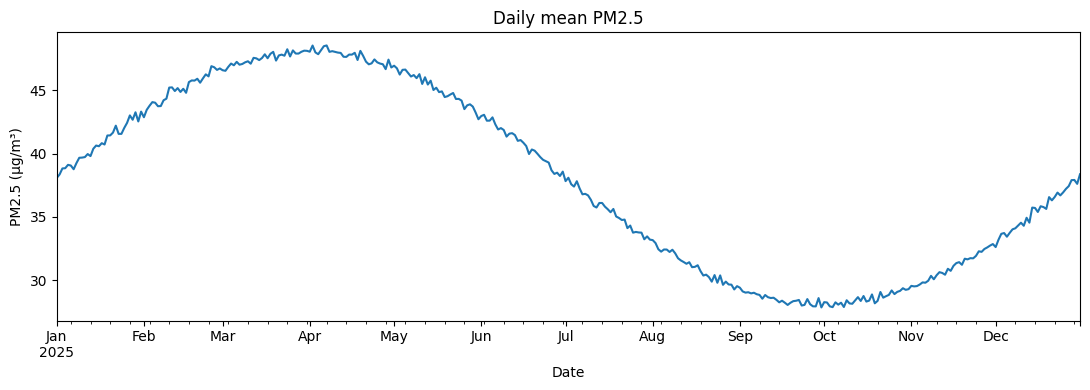

<Figure size 700x400 with 0 Axes>

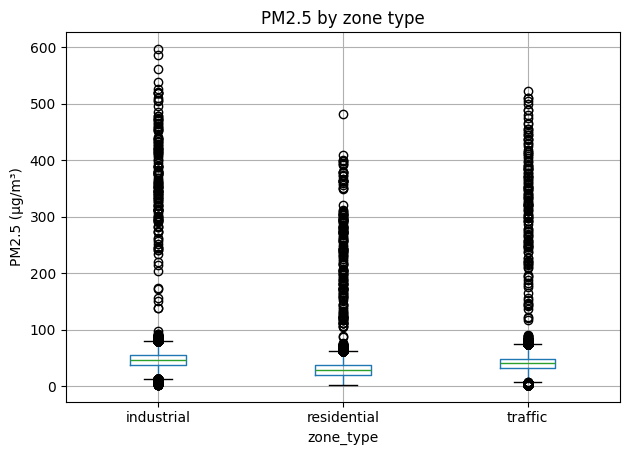

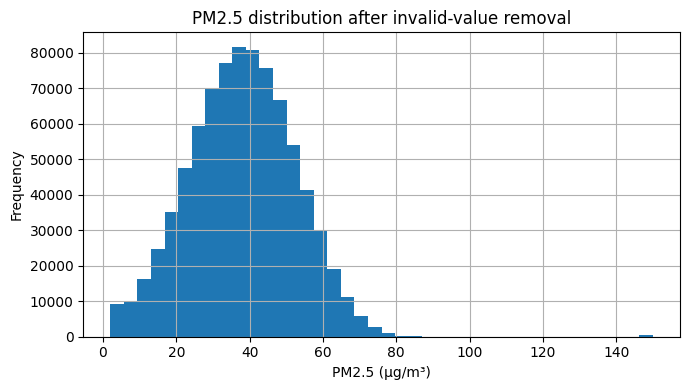

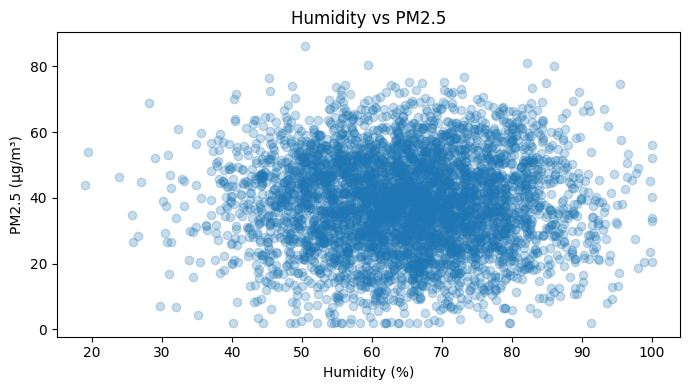

<Figure size 1000x400 with 0 Axes>

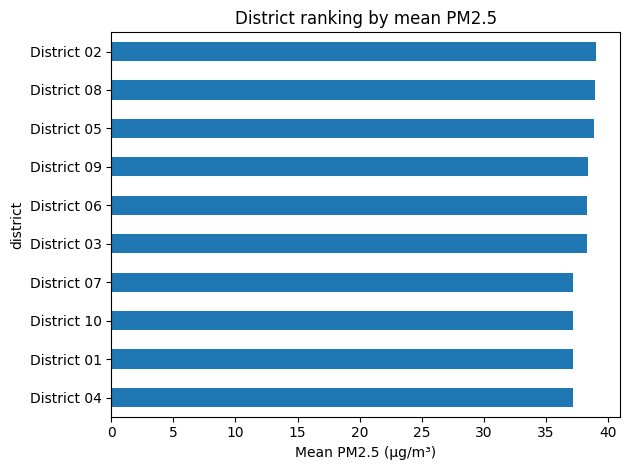

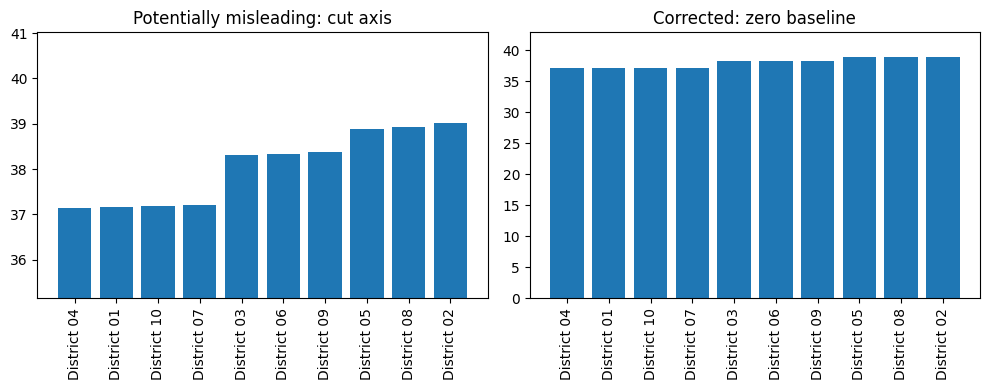

All figures saved in: air_quality_project/figures


In [11]:
# 1. PM2.5 time series
daily=valid.set_index("timestamp")["PM2.5"].resample("D").mean()
plt.figure(figsize=(11,4)); daily.plot(); plt.title("Daily mean PM2.5"); plt.ylabel("PM2.5 (µg/m³)"); plt.xlabel("Date"); plt.tight_layout(); plt.savefig(FIGURES/"task7_1_timeseries.png",dpi=150); plt.show()
# 2. Boxplot by zone
plt.figure(figsize=(7,4)); valid.boxplot(column="PM2.5",by="zone_type"); plt.title("PM2.5 by zone type"); plt.suptitle(""); plt.ylabel("PM2.5 (µg/m³)"); plt.tight_layout(); plt.savefig(FIGURES/"task7_2_boxplot.png",dpi=150); plt.show()
# 3. Histogram
plt.figure(figsize=(7,4)); clean["PM2.5"].dropna().clip(upper=150).hist(bins=40); plt.title("PM2.5 distribution after invalid-value removal"); plt.xlabel("PM2.5 (µg/m³)"); plt.ylabel("Frequency"); plt.tight_layout(); plt.savefig(FIGURES/"task7_3_histogram.png",dpi=150); plt.show()
# 4. Humidity vs PM2.5
sample_plot=valid.sample(min(5000,len(valid)),random_state=SEED)
plt.figure(figsize=(7,4)); plt.scatter(sample_plot.humidity_pct,sample_plot["PM2.5"],alpha=.25); plt.title("Humidity vs PM2.5"); plt.xlabel("Humidity (%)"); plt.ylabel("PM2.5 (µg/m³)"); plt.tight_layout(); plt.savefig(FIGURES/"task7_4_scatter.png",dpi=150); plt.show()
# 5. District ranking
plt.figure(figsize=(10,4)); district_summary.sort_values("mean_pm25").plot.barh(x="district",y="mean_pm25",legend=False); plt.title("District ranking by mean PM2.5"); plt.xlabel("Mean PM2.5 (µg/m³)"); plt.tight_layout(); plt.savefig(FIGURES/"task7_5_district_rank.png",dpi=150); plt.show()
# Misleading vs corrected: truncated y-axis vs zero baseline
vals=district_summary.sort_values("mean_pm25")
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].bar(vals.district,vals.mean_pm25); ax[0].set_ylim(vals.mean_pm25.min()-2,vals.mean_pm25.max()+2); ax[0].set_title("Potentially misleading: cut axis")
ax[1].bar(vals.district,vals.mean_pm25); ax[1].set_ylim(0,vals.mean_pm25.max()*1.1); ax[1].set_title("Corrected: zero baseline")
for a in ax: a.tick_params(axis="x",rotation=90)
plt.tight_layout(); plt.savefig(FIGURES/"task7_misleading_vs_corrected.png",dpi=150); plt.show()
print("All figures saved in:",FIGURES)

## TASK 8 – Reusable pre-processing program, validation and logging

In [12]:
logging.basicConfig(level=logging.INFO,format="%(levelname)s: %(message)s")
REQUIRED={"station_id","timestamp","PM2.5","PM10","NO2","temperature_C","humidity_pct"}
def read_month(path):
    data=pd.read_csv(path,parse_dates=["timestamp"])
    missing=REQUIRED-set(data.columns)
    if missing: raise ValueError(f"Missing required columns: {sorted(missing)}")
    logging.info("Rows read: %d",len(data))
    return data
def clean_month(data):
    before=len(data)
    out=data.drop_duplicates(["station_id","timestamp"]).copy()
    for col in numeric_cols:
        out.loc[out[col] < 0,col]=np.nan
    removed=before-len(out)
    logging.info("Duplicate rows removed: %d",removed)
    return out
def summarise_month(data):
    result=data.groupby("station_id")["PM2.5"].agg(["count","mean","max"]).reset_index()
    logging.info("Station summaries written: %d",len(result))
    return result
def run_pipeline(path, output_path):
    data=read_month(path)
    cleaned=clean_month(data)
    summary=summarise_month(cleaned)
    cleaned.to_csv(output_path,index=False)
    return cleaned,summary
cleaned_run,summary_run=run_pipeline(RAW/"supplier_A.csv",PROCESSED/"cleaned_month.csv")
display(summary_run.head())
# Hand-made test with known answer
toy=pd.DataFrame({"station_id":["A","A","A"],"timestamp":pd.to_datetime(["2025-01-01","2025-01-01","2025-01-02"],utc=True),
                  "PM2.5":[10,10,20],"PM10":[20,20,30],"NO2":[5,5,8],"temperature_C":[25,25,26],"humidity_pct":[50,50,55]})
toy_clean=clean_month(toy)
assert len(toy_clean)==2
assert toy_clean["PM2.5"].mean()==15
print("Toy test passed: duplicate removed and mean PM2.5 = 15.")
print("Output file:",PROCESSED/"cleaned_month.csv")

,station_id,count,mean,max
0,S001,8189,28.340935,371.636116
1,S002,8201,46.108564,439.153938
2,S003,8217,40.136425,438.383074
3,S004,8205,28.084708,242.624770
4,S005,8201,46.390641,432.209933


Toy test passed: duplicate removed and mean PM2.5 = 15.
Output file: air_quality_project/data/processed/cleaned_month.csv


## TASK 9 – Predict, then test

In [13]:
predictions=pd.DataFrame([
 ["Missing/invalid readings","About 10–15%","Injected missing, sentinel and impossible values"],
 ["Vectorised calculation speed-up","At least 2× faster","Array operations avoid Python-level row loops"],
 ["Scaling changes station ranking","Usually no, if one common monotonic scaler is applied","Monotonic scaling preserves order"],
 ["Interpolation changes district ranking","Possibly, but likely modest for short random gaps","Interpolation can change group means and sample counts"]
],columns=["Question","Prediction","Reason"])
display(predictions)
observed_missing=100*(1-clean[numeric_cols].notna().all(axis=1).mean())
speedup=loop_time/max(vector_time,1e-12)
print(f"Observed rows with at least one missing/invalid numeric value: {observed_missing:.2f}%")
print(f"Observed vectorisation speed-up: {speedup:.2f}x")
print("Compare the measured values with the predictions above; timing varies by computer.")

,Question,Prediction,Reason
0,Missing/invalid readings,About 10–15%,"Injected missing, sentinel and impossible values"
1,Vectorised calculation speed-up,At least 2× faster,Array operations avoid Python-level row loops
2,Scaling changes station ranking,"Usually no, if one common monotonic scaler is ...",Monotonic scaling preserves order
3,Interpolation changes district ranking,"Possibly, but likely modest for short random gaps",Interpolation can change group means and sampl...


Observed rows with at least one missing/invalid numeric value: 28.23%
Observed vectorisation speed-up: 123.12x
Compare the measured values with the predictions above; timing varies by computer.


## TASK 10 – Interpret, integrate and recommend

In [14]:
print("Top 5 stations by average PM2.5:")
display(station_summary.sort_values("rank").head(5))
print("Districts with highest average PM2.5:")
display(district_summary.sort_values("rank").head(5))
# Simple sensor flag: unusually high PM2.5 variability or extreme maximum
sensor_flags=station_summary[(station_summary.max_pm25>150) | (station_summary.mean_pm25>station_summary.mean_pm25.mean()+3*station_summary.mean_pm25.std())]
print("Potential sensor review candidates:",len(sensor_flags))
display(sensor_flags)
print("Recommendation: preserve raw files; validate schema; standardise units/time; remove duplicates and invalid values;")
print("use limited gap filling; aggregate with Pandas; save outputs and figures; log counts and runtime.")

Top 5 stations by average PM2.5:


,station_id,mean_pm25,max_pm25,readings,district,zone_type,rank
94,S095,46.435264,460.524469,8222,District 10,industrial,1
52,S053,46.432654,441.419855,8167,District 06,industrial,2
10,S011,46.430456,521.573600,8164,District 02,industrial,3
4,S005,46.391916,432.209933,8207,District 01,industrial,4
76,S077,46.329436,464.277812,8190,District 08,industrial,5


Districts with highest average PM2.5:


,district,mean_pm25,max_pm25,readings,rank
1,District 02,39.018353,521.573600,82070,1
7,District 08,38.932539,481.288069,82147,2
4,District 05,38.891379,518.862737,82104,3
8,District 09,38.367466,509.766749,82094,4
5,District 06,38.339946,585.645586,81925,5


Potential sensor review candidates: 100


,station_id,mean_pm25,max_pm25,readings,district,zone_type,rank
0,S001,28.340668,371.636116,8191,District 01,residential,69
1,S002,46.114908,439.153938,8204,District 01,industrial,22
2,S003,40.133134,438.383074,8220,District 01,traffic,50
3,S004,28.085344,242.624770,8208,District 01,residential,92
4,S005,46.391916,432.209933,8207,District 01,industrial,4
...,...,...,...,...,...,...,...
95,S096,40.176984,505.612885,8176,District 10,traffic,45
96,S097,28.203919,379.696597,8175,District 10,residential,80
97,S098,46.077506,434.188883,8204,District 10,industrial,27
98,S099,40.071225,480.127314,8175,District 10,traffic,56


Recommendation: preserve raw files; validate schema; standardise units/time; remove duplicates and invalid values;
use limited gap filling; aggregate with Pandas; save outputs and figures; log counts and runtime.


## TASK 11 – Day-4 design challenge: scale to 1,800 stations and minute-level data

In [15]:
# Demonstrate scaling with repeated copies (benchmark proxy; not a full 3-year minute dataset)
base_bench=clean.head(100_000).copy()
bench=[]
for multiplier in [1,10,50]:
    big=pd.concat([base_bench]*multiplier,ignore_index=True)
    t0=time.perf_counter()
    grouped=big.groupby("station_id",observed=True)["PM2.5"].mean()
    elapsed=time.perf_counter()-t0
    memory=big.memory_usage(deep=True).sum()/1024**2
    bench.append([multiplier,len(big),round(elapsed,3),round(memory,2)])
bench_df=pd.DataFrame(bench,columns=["copies","rows","groupby_seconds","memory_MB"])
display(bench_df)
# Chunked read strategy
chunks=[]
chunk_rows=100_000
for chunk in pd.read_csv(RAW/"supplier_A.csv",chunksize=chunk_rows,usecols=["station_id","timestamp","PM2.5"],parse_dates=["timestamp"]):
    chunk=chunk[chunk["PM2.5"].notna() & (chunk["PM2.5"]>=0)]
    chunks.append(chunk.groupby("station_id")["PM2.5"].agg(["sum","count"]))
partial=pd.concat(chunks).groupby(level=0).sum()
partial["mean_pm25"]=partial["sum"]/partial["count"]
print("Chunked station summaries:")
display(partial.head())
print("Design decision: MODIFY the original pipeline.")
print("- Use chunked reads and column projection to control memory.")
print("- Add a configurable supplier column/unit mapping layer and schema validation.")
print("- Use categorical IDs, float32 where precision tests permit, and vectorised operations.")
print("- Store cleaned data in partitioned Parquet (by year/month/district) for efficient re-use.")
print("- Run incremental weekly processing and publish district aggregates before detailed plots.")
print("- Keep exact raw files, processing logs, validation reports and reproducible configuration.")

,copies,rows,groupby_seconds,memory_MB
0,1,100000,0.006,4.68
1,10,1000000,0.030,46.74
2,50,5000000,0.169,233.66


Chunked station summaries:


,sum,count,mean_pm25
station_id,,,
S001,232138.413126,8191,28.340668
S002,378326.708397,8204,46.114908
S003,329894.359245,8220,40.133134
S004,230524.502822,8208,28.085344
S005,380738.452859,8207,46.391916


Design decision: MODIFY the original pipeline.
- Use chunked reads and column projection to control memory.
- Add a configurable supplier column/unit mapping layer and schema validation.
- Use categorical IDs, float32 where precision tests permit, and vectorised operations.
- Store cleaned data in partitioned Parquet (by year/month/district) for efficient re-use.
- Run incremental weekly processing and publish district aggregates before detailed plots.
- Keep exact raw files, processing logs, validation reports and reproducible configuration.


## Final submission checklist

- [ ] Run every cell from top to bottom in Colab.
- [ ] Check that all 11 task sections execute without errors.
- [ ] Download the generated `air_quality_project` folder or zip it for submission.
- [ ] Include the figures from the `figures` folder in the PDF report.
- [ ] Replace illustrative observations with the actual outputs from your Colab run.
- [ ] Mention clearly that the dataset is synthetic and explain the injected quality problems.

**Important:** This notebook is a complete working starting point. Runtime and memory figures depend on the computer/Colab session, so use your own measured outputs in the final report.